In [1]:
'''

making new eff data again but no satellites this time
'''

'\n\nmaking new eff data again but no satellites this time\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
#so we choose some data
#evenly distributed between bands and fields?
#or actually there are twice as many in i than g
#so two i one g one r
#let's use all the quadrants in case there are differences

In [9]:
filenames = ['ztf_20221020148032_000686_zg_c05_x_0002.',
          'ztf_20221020163819_000640_zg_c12_x_0001.',
          'ztf_20221020297847_000449_zr_c04_x_0011.',
          'ztf_20221020154120_000640_zi_c15_x_0028.',
          'ztf_20221020294271_000449_zr_c16_x_0012.',
          'ztf_20221020154120_000640_zi_c12_x_0028.',
          'ztf_20221020138241_000686_zi_c16_x_0001.',
          'ztf_20221020154120_000640_zi_c08_x_0014.',
          'ztf_20221020148032_000686_zg_c16_x_0014.',
           'ztf_20221020141806_000686_zi_c16_x_0020.']
#we're adding some extra here

In [19]:
# HERES WHERE THE STUFF HAPPENS
path_to_save_pos = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/full_image_implantations_pos/"
fpath_image = "/lustre/lrspec/ZTF_data/2022/1020/"
path_to_save_neg = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/full_image_implantations_neg/"
os.makedirs(path_to_save_neg, exist_ok=True)
os.makedirs(path_to_save_pos, exist_ok=True)
os.makedirs(path_to_save_neg+ "images/", exist_ok=True)
os.makedirs(path_to_save_pos+ "images/", exist_ok=True)
os.makedirs(path_to_save_neg+ "info/", exist_ok=True)
os.makedirs(path_to_save_pos+ "info/", exist_ok=True)

size=2*10*4*len(filenames)+1
seed = np.random.seed(20)  # so that i can keep the same random
# for the center of the transient - want at least half of the transient in the image
center_values = np.random.randint(35, high=3035, size=size, dtype=int)
sigmas = np.random.randint(3, high=10, size=size, dtype=int)
intensities_pos = imp.get_intensities_pos_feb(size, seed)
intensities_neg = imp.get_intensities_neg_feb(size, seed)
counter = 0

for fname in filenames:
    
    image_filename = fname+'fits.fz'
    filename_start = image_filename[:40]
    image_filename_full = fpath_image + image_filename
    print(image_filename)
    hdul = fits.open(image_filename_full)
    for iteration in range(1, 5):
        # if iteration in sat_df[sat_df['filename']==fname]['quad'].values: #don't use the ones with sats
        #     print(fname)
        #     print("skipping quad ", iteration)
        #     continue
        file1_array = hdul[iteration].data
        # norm = (file1_array - np.min(file1_array)) / (
            # np.max(file1_array) - np.min(file1_array)
        # )
        image = file1_array
        # plt.imshow(np.sqrt(image))
        # plt.show()
        nrow, ncol = image.shape
    
        for thetype in ["pos", "neg"]:
            # print(type)
                
            if thetype=="pos":
                imagepath = (
                    path_to_save_pos
                    + "images/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + ".npy")
                
                infopath = (
                    path_to_save_pos
                    + "info/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + "_info.npy")
                

                stamps_implanted, stamp_info, = imp.implant_10_transients(
                image, sigmas, intensities_pos, center_values, counter, norm=False
                ) 
                np.save(imagepath, stamps_implanted)
                np.save(infopath, stamp_info)
                counter += 10 
                
            elif thetype=="neg":
                imagepath = (
                    path_to_save_neg
                    + "images/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + ".npy")
                
                infopath = (
                    path_to_save_neg
                    + "info/"
                    + str(filename_start)
                    + "_"
                    + str(iteration)
                    + "_info.npy")
                

                stamps_implanted, stamp_info = imp.implant_10_transients(
                image, sigmas, intensities_neg, center_values, counter, norm=False
                ) 
                np.save(imagepath, stamps_implanted)
                np.save(infopath, stamp_info)
                counter += 10 


        

ztf_20221020148032_000686_zg_c05_x_0002.fits.fz
trans xcoord etc:  (385, 2557, 1.005, 9)
trans xcoord etc:  (557, 306, 1.2, 4)
trans xcoord etc:  (595, 3007, 1.005, 8)
trans xcoord etc:  (1237, 2476, 1.5, 9)
trans xcoord etc:  (1966, 1463, 1.01, 9)
trans xcoord etc:  (2080, 1849, 1.3, 6)
trans xcoord etc:  (2274, 1642, 1.05, 3)
trans xcoord etc:  (2468, 587, 1.1, 4)
trans xcoord etc:  (2496, 1528, 1.4, 4)
trans xcoord etc:  (2793, 509, 1.05, 5)
trans xcoord etc:  (385, 1853, 0.8, 3)
trans xcoord etc:  (557, 2846, 0.8, 6)
trans xcoord etc:  (595, 1014, 0.9, 6)
trans xcoord etc:  (1237, 1843, 0.99, 4)
trans xcoord etc:  (1966, 2848, 0.995, 7)
trans xcoord etc:  (2079, 2825, 0.9, 9)
trans xcoord etc:  (2274, 1203, 0.95, 4)
trans xcoord etc:  (2468, 652, 0.95, 5)
trans xcoord etc:  (2497, 810, 0.7, 4)
trans xcoord etc:  (2793, 520, 0.99, 9)
trans xcoord etc:  (94, 1314, 1.1, 8)
trans xcoord etc:  (265, 1065, 1.005, 5)
trans xcoord etc:  (340, 2365, 2.0, 6)
trans xcoord etc:  (341, 2013, 1.

In [30]:
os.listdir(path_to_save_pos+'info')

['ztf_20221020138241_000686_zi_c16_x_0001._4_info.npy',
 'ztf_20221020141806_000686_zi_c16_x_0020._4_info.npy',
 'ztf_20221020294271_000449_zr_c16_x_0012._2_info.npy',
 'ztf_20221020163819_000640_zg_c12_x_0001._1_info.npy',
 'ztf_20221020148032_000686_zg_c05_x_0002._3_info.npy',
 'ztf_20221020141806_000686_zi_c16_x_0020._3_info.npy',
 'ztf_20221020148032_000686_zg_c16_x_0014._2_info.npy',
 'ztf_20221020297847_000449_zr_c04_x_0011._2_info.npy',
 'ztf_20221020138241_000686_zi_c16_x_0001._3_info.npy',
 'ztf_20221020154120_000640_zi_c08_x_0014._2_info.npy',
 'ztf_20221020148032_000686_zg_c05_x_0002._4_info.npy',
 'ztf_20221020154120_000640_zi_c12_x_0028._1_info.npy',
 'ztf_20221020148032_000686_zg_c05_x_0002._2_info.npy',
 'ztf_20221020154120_000640_zi_c08_x_0014._4_info.npy',
 'ztf_20221020148032_000686_zg_c16_x_0014._4_info.npy',
 'ztf_20221020297847_000449_zr_c04_x_0011._4_info.npy',
 'ztf_20221020294271_000449_zr_c16_x_0012._3_info.npy',
 'ztf_20221020154120_000640_zi_c08_x_0014._3_inf

In [17]:
to_append = ["_0", "_1","_2","_3","_4"]
# In[68]:

path_start = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/full_image_implantations_pos/predsarrays_"
paths = [path_start*5]+to_append

In [19]:
paths = [path_start+a for a in to_append]

In [20]:
paths

['/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays__0',
 '/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays__1',
 '/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays__2',
 '/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays__3',
 '/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays__4']

In [20]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = path_to_save_pos+'info'
path_to_save = path_to_save_pos

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path)
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    infos = np.load(os.path.join(folder_path, f))
    filename_start = f[:40]
    filename_quad = f[41]
    # print(info)
    if counter == 0:
        df_implants["filename"] = np.full(len(infos),filename_start)
        df_implants["row_from_implant"] = infos[:,0]
        df_implants["col_from_implant"] = infos[:,1]
        df_implants["A_from_implant"] = infos[:,2]
        df_implants["sig_from_implant"] = infos[:,3]
        df_implants["quad_from_implant"] = np.full(len(infos),filename_quad)
        counter = 1
    else:
        print("adding")
        df_implants2 = pd.DataFrame([])
        df_implants2["filename"] = np.full(len(infos),filename_start)
        df_implants2["row_from_implant"] = infos[:,0]
        df_implants2["col_from_implant"] = infos[:,1]
        df_implants2["A_from_implant"] = infos[:,2]
        df_implants2["sig_from_implant"] = infos[:,3]
        df_implants2["quad_from_implant"] = np.full(len(infos),filename_quad)
        df_implants = pd.concat(
           [df_implants2, df_implants], ignore_index=True
                   )
# df_implants_neg = df_implants
    

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding


In [21]:
np.unique(df_implants['A_from_implant'], return_counts=True)

(array([1.005, 1.01 , 1.05 , 1.1  , 1.15 , 1.2  , 1.3  , 1.4  , 1.5  ,
        2.   ]),
 array([39, 40, 45, 34, 41, 35, 36, 45, 40, 45]))

In [22]:
df_implants.to_csv("/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/full_image_implantations_pos/df_implants_pos")


In [23]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = path_to_save_neg+'info'
path_to_save = path_to_save_neg

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path)
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    infos = np.load(os.path.join(folder_path, f))
    filename_start = f[:40]
    filename_quad = f[41]
    # print(info)
    if counter == 0:
        df_implants["filename"] = np.full(len(infos),filename_start)
        df_implants["row_from_implant"] = infos[:,0]
        df_implants["col_from_implant"] = infos[:,1]
        df_implants["A_from_implant"] = infos[:,2]
        df_implants["sig_from_implant"] = infos[:,3]
        df_implants["quad_from_implant"] = np.full(len(infos),filename_quad)
        counter = 1
    else:
        print("adding")
        df_implants2 = pd.DataFrame([])
        df_implants2["filename"] = np.full(len(infos),filename_start)
        df_implants2["row_from_implant"] = infos[:,0]
        df_implants2["col_from_implant"] = infos[:,1]
        df_implants2["A_from_implant"] = infos[:,2]
        df_implants2["sig_from_implant"] = infos[:,3]
        df_implants2["quad_from_implant"] = np.full(len(infos),filename_quad)
        df_implants = pd.concat(
           [df_implants2, df_implants], ignore_index=True
                   )
df_implants.to_csv("/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/full_image_implantations_neg/df_implants_neg")
# df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")

    

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding


In [24]:
np.unique(df_implants['A_from_implant'], return_counts=True)

(array([0.5  , 0.6  , 0.7  , 0.8  , 0.9  , 0.95 , 0.99 , 0.995]),
 array([52, 38, 47, 48, 52, 55, 49, 59]))

In [29]:
# df_implants.to_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_implants_neg")
# 

In [ ]:
#okay so we also want to extract the light curves which we're doing in a script
#and then we have to PCA them and filter them

In [28]:
! ls -f "/lustre/lrspec/ZTF_data/lightcurves/1020/" | head -10

.
..
lightcurve_ztf_20221020138241_000686_zi_c11_x_0023_4_1499_1443.csv
lightcurve_ztf_20221020148032_000686_zg_c13_x_0017_4_0671_2743.csv
lightcurve_ztf_20221020157697_000640_zi_c01_x_0007_2_2443_0934.csv
lightcurve_ztf_20221020138241_000686_zi_c04_x_0008_3_1088_0873.csv
lightcurve_ztf_20221020163819_000640_zg_c10_x_0015_1_0887_2547.csv
lightcurve_ztf_20221020157697_000640_zi_c14_x_0029_3_0703_2696.csv
lightcurve_ztf_20221020138241_000686_zi_c16_x_0002_1_2185_1935.csv
lightcurve_ztf_20221020154120_000640_zi_c14_x_0012_1_2079_1660.csv
ls: write error: Broken pipe


In [34]:
test = np.load("/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/spliced_concat_neg/lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0019_1039_time_adjusted_concat.npy")

In [38]:
%matplotlib inline

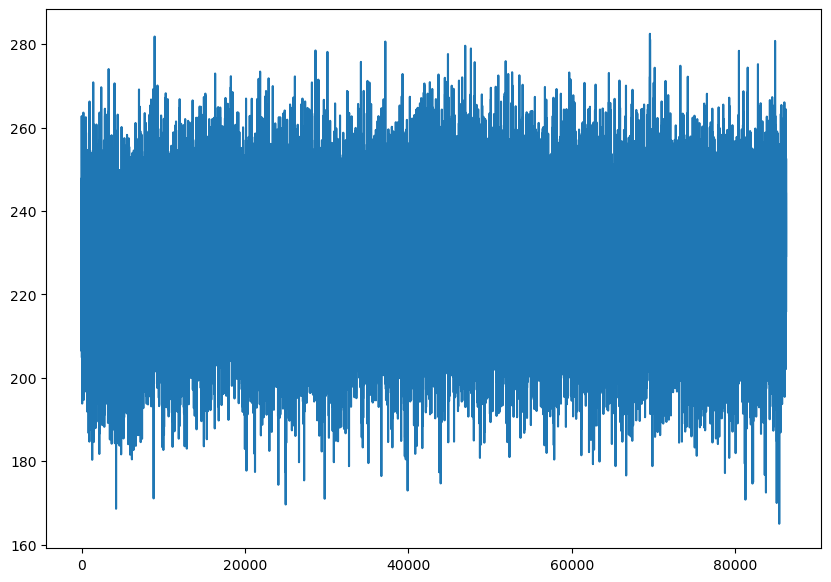

In [45]:
plt.plot(test)

# plt.xlim(0,3000)
plt.show()

In [41]:
test.shape

(86240,)

In [48]:
EFF_BASE   = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/"
posmap = pd.read_csv(os.path.join(EFF_BASE, f"spliced_mapping_pos.csv"))

In [51]:
negmap = pd.read_csv(os.path.join(EFF_BASE, f"spliced_mapping_neg.csv"))

In [57]:
negpath = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/spliced_concat_neg/"

(0.0, 3080.0)

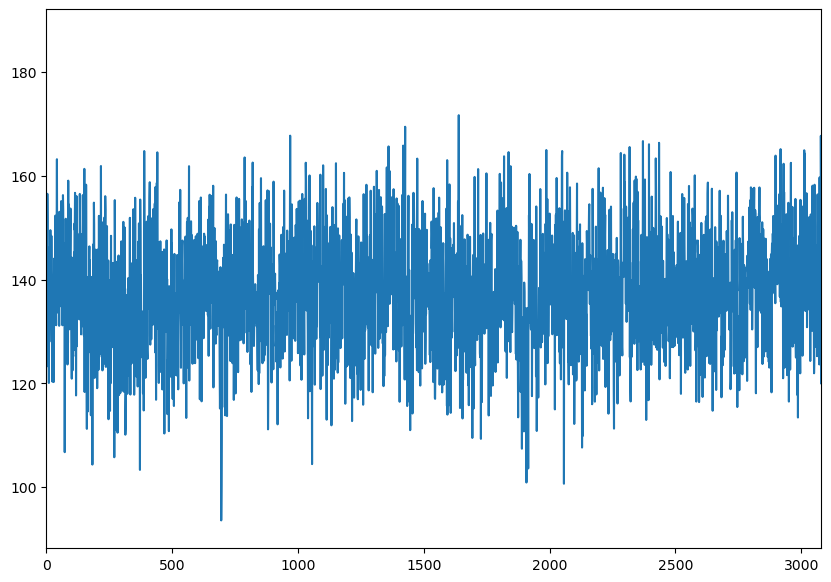

In [64]:
plt.plot(np.load(negpath+negmap[negmap['n_changed']>3000].iloc[2]['spliced_name']))
plt.xlim(0,3080)

In [62]:
negmap[negmap['n_changed']>3000].iloc[0]['impl_name']

'lightcurve_ztf_20221020138241_000686_zi_c16_x_0001._1.npy_1_1144_2420.csv'

In [56]:
negmap[negmap['n_changed']>3000]

,impl_name,pre,chunk,quad,impl_col,impl_y,status,spliced_name,clean_y,n_changed
0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1144,2420,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,2420,3073
1,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,1,2477,971,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,971,3080
2,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,2,1404,599,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,599,3080
3,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,1,751,2860,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,2860,3080
4,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,1,1974,1278,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,1278,3080
...,...,...,...,...,...,...,...,...,...,...
1982,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,3,1179,156,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,156,3080
1983,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,1,629,384,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,384,3080
1984,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,1,2874,622,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,622,3080
1985,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,ztf_20221020297847_000449_zr_c04_x,11,4,74,1538,ok,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,1538,3080


In [32]:
!ls "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/spliced_concat_neg"

lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0019_1039_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0037_2959_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0088_1376_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0137_2911_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0153_2686_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0180_1311_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0218_0665_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0267_2863_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0301_0839_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0343_0888_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0391_0842_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_00

In [129]:
def add_implant_cols(df_map, df_impl, col_tol=5):
    # parse implants: "ztf_..._x_0001." -> pre="ztf_..._x", chunk=1
    parsed = df_impl["filename"].str.extract(r"^(?P<pre>.+_x)_(?P<chunk>\d{4})\.$")
    imp = df_impl.copy()
    imp["pre"] = parsed["pre"]
    imp["chunk"] = parsed["chunk"].astype("Int64")
    imp["quad"] = imp["quad_from_implant"].astype("Int64")
    imp["implant_idx"] = imp.index            # remember which implant row was used
    n_unparsed = imp["pre"].isna().sum()
    if n_unparsed:
        print(f"WARNING: {n_unparsed} implant filenames didn't parse")
    imp = imp.dropna(subset=["pre", "chunk", "quad"])
    imp["chunk"] = imp["chunk"].astype(int)
    imp["quad"] = imp["quad"].astype(int)

    m = df_map.copy()
    m["map_idx"] = m.index

    cand = m.merge(imp, on=["pre", "chunk", "quad"], how="left", suffixes=("", "_imp"))
    cand["dcol_match"] = cand["row_from_implant"] - cand["impl_col"]
    cand = cand[cand["row_from_implant"].isna() | (cand["dcol_match"].abs() <= col_tol)]

    # how many implants fall within tolerance of each map row
    cand["n_cand"] = cand.groupby("map_idx")["implant_idx"].transform("count")

    # nearest implant per map row
    cand["absd"] = cand["dcol_match"].abs().fillna(np.inf)
    best = (cand.sort_values(["map_idx", "absd"])
                .drop_duplicates("map_idx", keep="first")
                .drop(columns=["absd"]))

    out = m.merge(best[["map_idx", "implant_idx", "n_cand", "dcol_match", "row_from_implant",
                        "col_from_implant", "A_from_implant", "sig_from_implant", "quad_from_implant"]],
                  on="map_idx", how="left").drop(columns="map_idx")
    out["n_cand"] = out["n_cand"].fillna(0).astype(int)

    # diagnostics
    print("map rows with no implant match:", (out["implant_idx"].isna()).sum())
    print("map rows with >1 implant within tol:", (out["n_cand"] > 1).sum())
    dup = out["implant_idx"].dropna().duplicated(keep=False).sum()
    print("map rows sharing the same implant row:", dup)
    print("implants never matched:", len(imp) - out["implant_idx"].nunique())
    print(out["dcol_match"].value_counts().sort_index())
    return out

df_map_neg_full = add_implant_cols(negmap, df_implants_neg, col_tol=5)

map rows with no implant match: 1600
map rows with >1 implant within tol: 6
map rows sharing the same implant row: 0
implants never matched: 13
-3.0      1
-2.0      4
-1.0     39
 0.0    211
 1.0    127
 2.0      5
Name: dcol_match, dtype: int64


In [128]:
df_map_pos_full = add_implant_cols(negmap, df_implants_pos, col_tol=5)

map rows with no implant match: 1601
map rows with >1 implant within tol: 7
map rows sharing the same implant row: 0
implants never matched: 14
-4.0      1
-2.0      3
-1.0     33
 0.0    219
 1.0    125
 2.0      5
Name: dcol_match, dtype: int64


In [95]:
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/full_image_implantations_pos/df_implants_pos")


In [91]:
df_map_neg_full

,impl_name,pre,chunk,quad,impl_col,impl_y,status,spliced_name,clean_y,n_changed,implant_idx,n_cand,dcol_match,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1144,2420,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,2420,3073,43.0,1,0.0,1144.0,870.0,0.99,8.0,1.0
1,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,1,2477,971,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,971,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,2,1404,599,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,599,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
3,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,1,751,2860,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,2860,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
4,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,1,1974,1278,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,1278,3080,38.0,1,1.0,1975.0,904.0,0.80,5.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1982,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,3,1179,156,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,156,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1983,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,1,629,384,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,384,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1984,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,1,2874,622,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,622,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1985,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,ztf_20221020297847_000449_zr_c04_x,11,4,74,1538,ok,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,1538,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


In [92]:
df_implants_neg

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,0,ztf_20221020163819_000640_zg_c12_x_0001.,25.0,103.0,0.500,5.0,3
1,1,ztf_20221020163819_000640_zg_c12_x_0001.,246.0,2741.0,0.600,8.0,3
2,2,ztf_20221020163819_000640_zg_c12_x_0001.,286.0,1324.0,0.800,5.0,3
3,3,ztf_20221020163819_000640_zg_c12_x_0001.,628.0,1500.0,0.995,4.0,3
4,4,ztf_20221020163819_000640_zg_c12_x_0001.,771.0,1201.0,0.995,5.0,3
...,...,...,...,...,...,...,...
395,395,ztf_20221020148032_000686_zg_c16_x_0014.,1368.0,1044.0,0.990,6.0,4
396,396,ztf_20221020148032_000686_zg_c16_x_0014.,1695.0,2567.0,0.500,9.0,4
397,397,ztf_20221020148032_000686_zg_c16_x_0014.,2298.0,265.0,0.800,6.0,4
398,398,ztf_20221020148032_000686_zg_c16_x_0014.,2837.0,61.0,0.900,7.0,4


In [73]:
df_map_pos

,impl_name,pre,chunk,quad,impl_col,impl_y,status,spliced_name,clean_y,n_changed
0,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,ztf_20221020148032_000686_zg_c05_x,2,4,587,1000,ok,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,1000,3079
1,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,4,1781,2303,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,2303,3080
2,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,ztf_20221020297847_000449_zr_c04_x,11,3,2039,1080,ok,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,1080,104
3,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,3,1951,669,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,669,3080
4,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,4,1429,1960,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,1960,3080
...,...,...,...,...,...,...,...,...,...,...
1982,lightcurve_ztf_20221020154120_000640_zi_c12_x_...,ztf_20221020154120_000640_zi_c12_x,28,3,6,1767,ok,lightcurve_ztf_20221020154120_000640_zi_c12_x_...,1767,3080
1983,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,4,1310,473,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,473,3080
1984,lightcurve_ztf_20221020148032_000686_zg_c16_x_...,ztf_20221020148032_000686_zg_c16_x,14,3,2659,2745,ok,lightcurve_ztf_20221020148032_000686_zg_c16_x_...,2745,3080
1985,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1006,991,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,991,3080


In [72]:
def diagnose(r, kind, win=50, max_lag=10):
    quad, col_s, y_s = re.search(r"_0000_(\d+)_(\d+)_(\d+)_time_adjusted", r.spliced_name).groups()
    clean = load_chunk(f"{CLEAN_DIR}lightcurve_{r.pre}_{r.chunk:04d}_{quad}_{col_s}_{y_s}.csv")
    imp   = load_chunk(IMPL_DIR[kind] + r.impl_name)
    d = imp - clean
    sig = 1.4826 * np.median(np.abs(clean - np.median(clean)))      # robust noise of clean chunk

    k = np.argmax(np.abs(d))                                        # injection location, roughly
    mask = np.ones(len(d), bool); mask[max(0, k-win):k+win] = False
    slope, icpt = np.polyfit(clean, imp, 1)
    lags = range(-max_lag, max_lag + 1)
    cc = [np.corrcoef(clean[max_lag:-max_lag], np.roll(imp, l)[max_lag:-max_lag])[0, 1] for l in lags]

    return dict(
        sig=sig,
        med_abs_d_over_sig=np.median(np.abs(d)) / sig,       # typical difference vs noise
        std_d_outside_over_sig=np.std(d[mask]) / sig,        # difference away from the injection
        mean_d_outside_over_sig=np.mean(d[mask]) / sig,      # constant offset?
        slope=slope, intercept=icpt,                         # imp = slope*clean + intercept
        corr0=np.corrcoef(clean, imp)[0, 1],
        best_lag=list(lags)[int(np.argmax(cc))], corr_best=max(cc),
        frac_gt_1e6=np.mean(np.abs(d) > 1e-6),
        frac_gt_0p1sig=np.mean(np.abs(d) > 0.1 * sig),
        dcol=r.impl_col - int(col_s), dy=r.impl_y - int(y_s),
        max_abs_d_over_sig = np.max(np.abs(d))/sig,
        # difference_from_row = abs(np.argmax(np.abs(d)) - row_from_implant)
    )

sample = df_map_pos[df_map_pos.spliced_name.notna()].sample(200, random_state=0)
diag = pd.DataFrame([diagnose(r, "pos") for r in sample.itertuples()])
print(diag.describe().T)

                         count       mean        std         min        25%  \
sig                      200.0  20.731809  40.417766    8.870195  11.083227   
med_abs_d_over_sig       200.0   0.000026   0.000031    0.000000   0.000000   
std_d_outside_over_sig   200.0   0.000031   0.000428    0.000000   0.000000   
mean_d_outside_over_sig  200.0  -0.000024   0.000041   -0.000150  -0.000043   
slope                    200.0   1.001111   0.012293    0.920207   1.000000   
intercept                200.0  -1.928428  26.751814 -261.376183  -0.000687   
corr0                    200.0   0.972378   0.093395    0.380190   1.000000   
best_lag                 200.0   0.000000   0.000000    0.000000   0.000000   
corr_best                200.0   0.972289   0.093648    0.378583   1.000000   
frac_gt_1e6              200.0   0.705617   0.443814    0.000000   0.021266   
frac_gt_0p1sig           200.0   0.002065   0.004713    0.000000   0.000000   
dcol                     200.0   0.000000   0.000000

In [29]:
# #i put the splicing in a script and then we can look at some of them
#    df_map.to_csv(os.path.join(EFF_BASE, f"spliced_mapping_{kind}.csv"), index=False)
#SPLICE_DIR = {k: EFF_BASE + f"spliced_concat_{k}/" for k in IMPL_DIR}
#EFF_BASE   = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/"
#CONCAT_DIR = "/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/"


#2. Run your denoising script

#Run it once per set, changing only original_direc to SPLICE_DIR[kind] 
#and new_direc to a new output folder (e.g. .../denoised_pos/). 
#The spliced file has exactly the same name as the clean chunk-0000 concat file it replaces, so grouping by filestart and the predictions lookup behave as in production.

#3. Measure SNR on the denoised output

  0%|          | 7/1987 [00:14<55:52,  1.69s/it]  

had an issue: lightcurve_ztf_20221020148032_000686_zg_c05_x_0000_1_1939_1246_time_adjusted_concat.npy ParserError("Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.")


  1%|          | 11/1987 [00:22<1:06:00,  2.00s/it]

had an issue: lightcurve_ztf_20221020154120_000640_zi_c15_x_0000_3_1744_0604_time_adjusted_concat.npy ParserError("Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.")




KeyboardInterrupt



In [ ]:
# DF_RE = re.compile(r"^(?P<pre>.+_x)_(?P<chunk>\d{4})\.$")

# def measure_snr_denoised(df, df_map, denoised_dir, flip_sign=False, col_tol=5, n=3080):
#     # denoised names are f'{filestart}_{fname[:-4]}_denoised'; key on the part from the last 'lightcurve_'
#     den = {fn[fn.rfind("lightcurve_"):]: os.path.join(denoised_dir, fn) for fn in os.listdir(denoised_dir)}

#     mp = defaultdict(list)
#     for r in df_map[df_map["spliced_name"].notna()].itertuples():
#         mp[(r.pre, r.chunk, r.quad)].append(r)

#     cache, results = {}, []
#     for _, r in tqdm(df.iterrows(), total=len(df)):
#         res = dict.fromkeys(out_cols, np.nan)
#         res.update(impl_name=None, dcol=np.nan, status="ok")
#         try:
#             m = DF_RE.match(r["filename"])
#             c, q = int(m["chunk"]), int(r["quad_from_implant"])
#             col = int(r["col_from_implant"])
#             cands = [x for x in mp.get((m["pre"], c, q), []) if abs(x.impl_col - col) <= col_tol]
#             if not cands:
#                 res["status"] = "no implanted LC match"
#             else:
#                 best = min(cands, key=lambda x: abs(x.impl_col - col))
#                 res["impl_name"], res["dcol"] = best.impl_name, best.impl_col - col
#                 if len(cands) > 1:
#                     res["status"] = f"{len(cands)} within +/-{col_tol}, used nearest"
#                 key = best.spliced_name[:-4] + "_denoised"
#                 if key not in den:
#                     res["status"] = "no denoised output (binary-excluded?)"
#                 else:
#                     if key not in cache:
#                         cache[key] = pd.read_csv(den[key], header=None)[0].to_numpy()
#                     full = cache[key]
#                     start = c * n - int(best.clean_y)
#                     if start < 0 or start + n > len(full):
#                         res["status"] = "chunk at array edge"
#                     else:
#                         tot = full[start:start + n]
#                         if flip_sign:
#                             tot = -tot
#                         out = get_snr_dimmest(tot, np.array([int(r["row_from_implant"])]))
#                         res.update(dict(zip(out_cols, out)))
#         except Exception as e:
#             res["status"] = f"error: {e!r}"
#         results.append(res)
#     return pd.concat([df.reset_index(drop=True), pd.DataFrame(results)], axis=1)

# df_implants_neg_snr = measure_snr_denoised(df_implants_neg, df_map_neg, "<denoised_neg_dir>", flip_sign=False)
# df_implants_pos_snr = measure_snr_denoised(df_implants_pos, df_map_pos, "<denoised_pos_dir>", flip_sign=True)

In [101]:
df_map_neg_full.iloc[0]

impl_name            lightcurve_ztf_20221020138241_000686_zi_c16_x_...
pre                                 ztf_20221020138241_000686_zi_c16_x
chunk                                                                1
quad                                                                 1
impl_col                                                          1144
impl_y                                                            2420
status                                                              ok
spliced_name         lightcurve_ztf_20221020138241_000686_zi_c16_x_...
clean_y                                                           2420
n_changed                                                         3073
implant_idx                                                       43.0
n_cand                                                               1
dcol_match                                                         0.0
row_from_implant                                                1144.0
col_fr

In [104]:
df_map_pos_full

,impl_name,pre,chunk,quad,impl_col,impl_y,status,spliced_name,clean_y,n_changed,implant_idx,n_cand,dcol_match,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1144,2420,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,2420,3073,143.0,1,0.0,1144.0,1412.0,1.4,6.0,1.0
1,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,1,2477,971,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,971,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,2,1404,599,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,599,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
3,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,1,751,2860,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,2860,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
4,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,1,1974,1278,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,1278,3080,158.0,1,1.0,1975.0,2477.0,1.4,7.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1982,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,3,1179,156,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,156,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1983,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,ztf_20221020154120_000640_zi_c15_x,28,1,629,384,ok,lightcurve_ztf_20221020154120_000640_zi_c15_x_...,384,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1984,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,1,2874,622,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,622,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1985,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,ztf_20221020297847_000449_zr_c04_x,11,4,74,1538,ok,lightcurve_ztf_20221020297847_000449_zr_c04_x_...,1538,3080,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


In [107]:
negs = df_map_neg_full.dropna(subset=["implant_idx"])
poss = df_map_pos_full.dropna(subset=["implant_idx"])

In [115]:
negs.iloc[0]['spliced_name']

'lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_1_1144_2420_time_adjusted_concat.npy'

In [114]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/denoised_lcs_neg/ | head -10

lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0019_1039_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0037_2959_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0088_1376_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0137_2911_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0180_1311_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0218_0665_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0267_2863_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c

In [150]:
lcfpath = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/denoised_lcs_pos/"
column_names_brightening = ['snr_local', 'snr_global_brightening', 'noise_local_brightening', 'noise_global_brightening', 
                'local_average_outside_brightening', 'height_brightening', 'FWHM_brightening', 'signal_local_brightening', 'central_point_brightening','point_left_brightening', 'point_right_brightening']
for index, dfrow in poss.iterrows():
    break
    tot = pd.read_csv(lcfpath+dfrow['spliced_name'][:-4]+'_denoised')
    break
    aggrows = dfrow['row_from_implant']
    rff.add_snr_brightest(negs, lcfpath)
    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute, point_left, point_right = get_snr_dimmest(tot, aggrows)                    
    df.loc[index, column_names_brightening] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute, point_left, point_right]


In [134]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/denoised_lcs_pos/lightcurve_ztf_20221020138241_000686_zi_*

^C


In [127]:
pd.read_csv('/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/denoised_lcs_neg/lightcurve_ztf_20221020138241_000686_zi_c09_lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_0019_1039_time_adjusted_concat_denoised', names=['flux'])

,flux
0,380.819993
1,379.359110
2,349.293415
3,348.506237
4,365.506138
...,...
86235,359.788965
86236,356.447698
86237,381.422090
86238,389.169247


In [151]:

lcfpath = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/denoised_lcs_pos/"
# flip_sign = True            # pos injections; False for neg
pos_col = "col_from_implant"  # CHECK: use whichever of row/col_from_implant matched argmax|d| earlier
n = 3080

# map "lightcurve_..._time_adjusted_concat_denoised" -> full path, ignoring the filestart prefix
den = {fn[fn.rfind("lightcurve_"):]: os.path.join(lcfpath, fn) for fn in os.listdir(lcfpath)}

poss = df_map_pos_full.dropna(subset=["implant_idx"]).copy()
cols = column_names_brightening
poss[cols] = np.nan
poss["snr_status"] = "ok"

cache = {}
for index, dfrow in poss.iterrows():
    key = dfrow["spliced_name"][:-4] + "_denoised"
    if key not in den:
        poss.loc[index, "snr_status"] = "no denoised output"
        continue
    if key not in cache:
        cache[key] = pd.read_csv(den[key], header=None)[0].to_numpy()
    full = cache[key]

    start = int(dfrow["chunk"]) * n - int(dfrow["clean_y"])
    if start < 0 or start + n > len(full):
        poss.loc[index, "snr_status"] = "chunk at array edge"
        continue

    tot = full[start:start + n]
    aggrows = np.array([int(dfrow[pos_col])])
    out = rff.get_snr_brightest(tot, aggrows)
    poss.loc[index, cols] = out

In [187]:

lcfpath = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/denoised_lcs_neg/"
# flip_sign = True            # pos injections; False for neg
pos_col = "col_from_implant"  # CHECK: use whichever of row/col_from_implant matched argmax|d| earlier
n = 3080

# map "lightcurve_..._time_adjusted_concat_denoised" -> full path, ignoring the filestart prefix
den = {fn[fn.rfind("lightcurve_"):]: os.path.join(lcfpath, fn) for fn in os.listdir(lcfpath)}

negs = df_map_neg_full.dropna(subset=["implant_idx"]).copy()
cols = column_names_brightening
negs[cols] = np.nan
negs["snr_status"] = "ok"

cache = {}
for index, dfrow in negs.iterrows():
    key = dfrow["spliced_name"][:-4] + "_denoised"
    if key not in den:
        negs.loc[index, "snr_status"] = "no denoised output"
        continue
    if key not in cache:
        cache[key] = pd.read_csv(den[key], header=None)[0].to_numpy()
    full = cache[key]

    start = int(dfrow["chunk"]) * n - int(dfrow["clean_y"])
    if start < 0 or start + n > len(full):
        negs.loc[index, "snr_status"] = "chunk at array edge"
        continue

    tot = full[start:start + n]
    aggrows = np.array([int(dfrow[pos_col])])
    out = rff.get_snr_dimmest(tot, aggrows)
    negs.loc[index, cols] = out

In [141]:
np.unique(poss['snr_status'], return_counts=True)

(array(['chunk at array edge', 'no denoised output', 'ok'], dtype=object),
 array([ 75,  10, 301]))

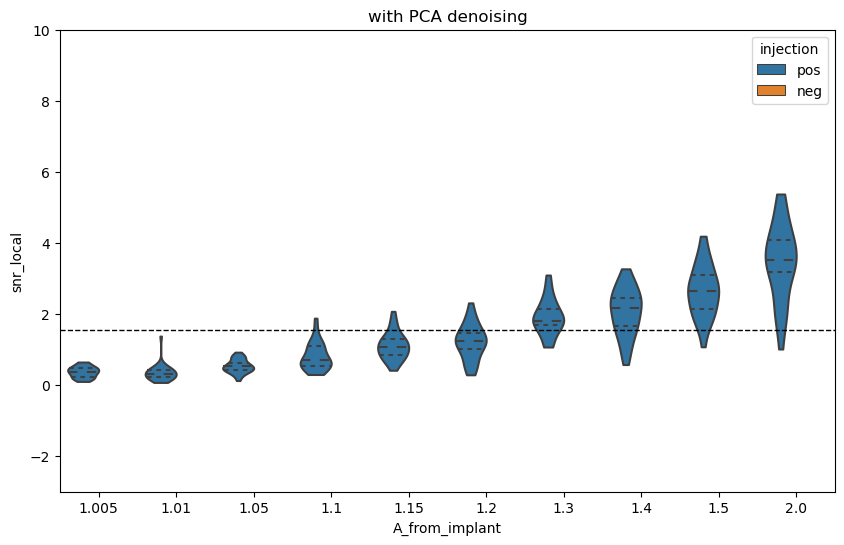

In [152]:
import seaborn as sns


df_plot = poss.assign(kind="pos")
# df_plot = pd.concat([a, b], ignore_index=True)
df_plot = df_plot[df_plot["snr_local"].notna()]

order = sorted(df_plot["A_from_implant"].unique())

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(
    data=df_plot, x="A_from_implant", y="snr_local", hue="kind",
    order=order, hue_order=["pos", "neg"],
    split=False, inner="quartile", cut=0, density_norm="count", ax=ax,
)
ax.axhline(1.55, color="k", ls="--", lw=1)
ax.set_ylim(-3,10)
ax.set_xlabel("A_from_implant")
ax.set_ylabel("snr_local")
ax.legend(title="injection")
plt.title("with PCA denoising")
plt.show()

In [156]:
!ls -f /lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/spliced_concat_neg | head -10

.
..
lightcurve_ztf_20221020141806_000686_zi_c10_x_0000_4_1749_0962_time_adjusted_concat.npy
lightcurve_ztf_20221020157697_000640_zi_c14_x_0000_1_2466_0290_time_adjusted_concat.npy
lightcurve_ztf_20221020141806_000686_zi_c14_x_0000_1_1484_1087_time_adjusted_concat.npy
lightcurve_ztf_20221020141806_000686_zi_c16_x_0000_4_1400_1624_time_adjusted_concat.npy
lightcurve_ztf_20221020141806_000686_zi_c05_x_0000_4_2029_2924_time_adjusted_concat.npy
lightcurve_ztf_20221020138241_000686_zi_c15_x_0000_2_2891_1455_time_adjusted_concat.npy
lightcurve_ztf_20221020163819_000640_zg_c16_x_0000_2_1971_1474_time_adjusted_concat.npy
lightcurve_ztf_20221020154120_000640_zi_c08_x_0000_4_1332_2625_time_adjusted_concat.npy
ls: write error: Broken pipe


In [ ]:
lightcurve_ztf_20221020141806_000686_zi_c10_x_0000_4_1749_0962_time_adjusted_concat.npy

In [182]:

lcfpath = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/spliced_concat_neg/"
# flip_sign = True            # pos injections; False for neg
pos_col = "col_from_implant"  # CHECK: use whichever of row/col_from_implant matched argmax|d| earlier
n = 3080

# map "lightcurve_..._time_adjusted_concat_denoised" -> full path, ignoring the filestart prefix
den = {fn[fn.rfind("lightcurve_"):]: os.path.join(lcfpath, fn) for fn in os.listdir(lcfpath)}

negs_nopca = df_map_neg_full.dropna(subset=["implant_idx"]).copy()
cols = column_names_brightening
negs_nopca[cols] = np.nan
negs_nopca["snr_status"] = "ok"

cache = {}
for index, dfrow in negs_nopca.iterrows():
    key = dfrow["spliced_name"] #[:-4] + "_denoised"
    if key not in den:
        negs_nopca.loc[index, "snr_status"] = "no denoised output"
        continue
    if key not in cache:
        cache[key] = np.load(den[key])
    full = cache[key]

    start = int(dfrow["chunk"]) * n - int(dfrow["clean_y"])
    if start < 0 or start + n > len(full):
        negs_nopca.loc[index, "snr_status"] = "chunk at array edge"
        continue

    tot = full[start:start + n]
    aggrows = np.array([int(dfrow[pos_col])])
    out = rff.get_snr_dimmest(tot, aggrows)
    negs_nopca.loc[index, cols] = out

In [162]:

lcfpath = "/lustre/lrspec/ZTF_data/efficiency_testing/oneperstreak_eff_data/spliced_concat_pos/"
# flip_sign = True            # pos injections; False for neg
pos_col = "col_from_implant"  # CHECK: use whichever of row/col_from_implant matched argmax|d| earlier
n = 3080

# map "lightcurve_..._time_adjusted_concat_denoised" -> full path, ignoring the filestart prefix
den = {fn[fn.rfind("lightcurve_"):]: os.path.join(lcfpath, fn) for fn in os.listdir(lcfpath)}

poss_nopca = df_map_pos_full.dropna(subset=["implant_idx"]).copy()
cols = column_names_brightening
poss_nopca[cols] = np.nan
poss_nopca["snr_status"] = "ok"

cache = {}
for index, dfrow in poss_nopca.iterrows():
    key = dfrow["spliced_name"] #[:-4] + "_denoised"
    if key not in den:
        poss_nopca.loc[index, "snr_status"] = "no denoised output"
        continue
    if key not in cache:
        cache[key] = np.load(den[key])
    full = cache[key]

    start = int(dfrow["chunk"]) * n - int(dfrow["clean_y"])
    if start < 0 or start + n > len(full):
        poss_nopca.loc[index, "snr_status"] = "chunk at array edge"
        continue

    tot = full[start:start + n]
    aggrows = np.array([int(dfrow[pos_col])])
    out = rff.get_snr_brightest(tot, aggrows)
    poss_nopca.loc[index, cols] = out

In [160]:
poss_nopca

,impl_name,pre,chunk,quad,impl_col,impl_y,status,spliced_name,clean_y,n_changed,...,noise_local_brightening,noise_global_brightening,local_average_outside_brightening,height_brightening,FWHM_brightening,signal_local_brightening,central_point_brightening,point_left_brightening,point_right_brightening,snr_status
0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1144,2420,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,2420,3073,...,15.892234,16.724561,437.168891,31.987695,1.0,5.655767,1408.0,1408.0,1409.0,ok
4,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,1,1974,1278,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,1278,3080,...,48.526721,51.309842,1799.115451,110.959744,2.0,13.900642,2486.0,2486.0,2488.0,ok
23,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,3,581,841,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,841,1300,...,212.164870,229.782367,7523.857305,419.250605,2.0,26.379429,2192.0,2191.0,2193.0,ok
24,lightcurve_ztf_20221020154120_000640_zi_c12_x_...,ztf_20221020154120_000640_zi_c12_x,28,2,3030,2329,ok,lightcurve_ztf_20221020154120_000640_zi_c12_x_...,2329,3079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,chunk at array edge
28,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,2,1888,2946,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,2946,3080,...,18.464532,19.268690,536.914252,42.794000,1.0,6.541712,1820.0,1820.0,1821.0,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1963,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,ztf_20221020148032_000686_zg_c05_x,2,2,448,1615,ok,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,1615,3079,...,23.173919,22.151341,699.271845,29.763189,2.0,7.042279,1965.0,1965.0,1967.0,ok
1964,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1797,221,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,221,3077,...,16.785794,17.562611,455.217168,14.805354,1.0,3.847773,1893.0,1893.0,1894.0,ok
1968,lightcurve_ztf_20221020294271_000449_zr_c16_x_...,ztf_20221020294271_000449_zr_c16_x,12,1,2271,1530,ok,lightcurve_ztf_20221020294271_000449_zr_c16_x_...,1530,3080,...,14.980688,13.528412,305.459186,16.087323,2.0,5.216770,192.0,191.0,193.0,ok
1969,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,ztf_20221020163819_000640_zg_c12_x,1,2,2060,325,ok,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,325,2853,...,108.424646,189.458826,4808.006138,113.847866,1.0,10.669952,2747.0,2747.0,2748.0,ok


ValueError: Could not interpret input 'kind'

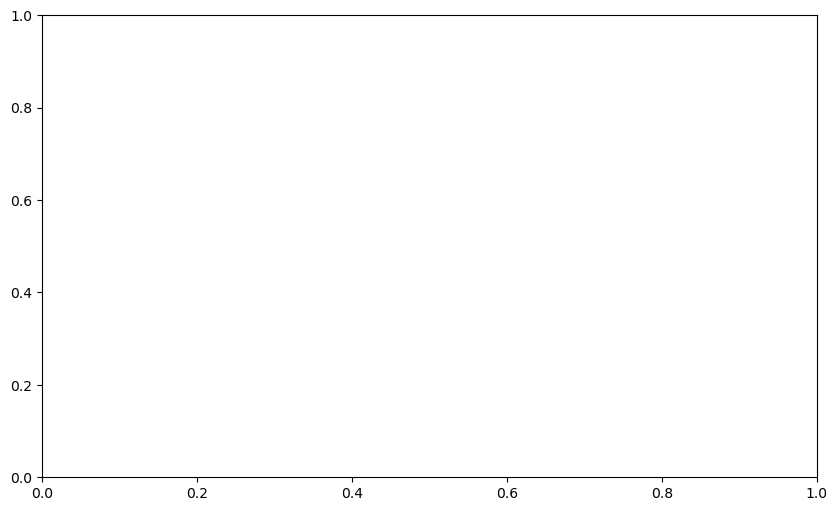

In [184]:

wpca = pd.concat([poss, negs], ignore_index=True)
nopca = pd.concat([poss_nopca, negs_nopca], ignore_index=True)
nopca.assign(kind="no pca")
wpca.assign(kind="with pca")
df_plot = pd.concat([nopca, wpca], ignore_index=True)
df_plot = df_plot[df_plot["snr_local"].notna()]

order = sorted(df_plot["A_from_implant"].unique())

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(
    data=df_plot, x="A_from_implant", y="snr_local", hue="kind",
    order=order, hue_order=["no pca", "with pca"],
    split=False, inner="quartile", cut=0, density_norm="count", ax=ax,
)
ax.axhline(1.55, color="k", ls="--", lw=1)
ax.set_ylim(-3,10)
ax.set_xlabel("A_from_implant")
ax.set_ylabel("snr_local")
ax.legend(title="injection")
plt.title("checking effect of pca on snr")
plt.show()

In [168]:
print((poss_nopca["noise_global_brightening"] - poss["noise_global_brightening"]).abs().describe())

count    301.000000
mean       3.451998
std       12.772012
min        0.000100
25%        0.034570
50%        0.093007
75%        0.389828
max      180.428426
Name: noise_global_brightening, dtype: float64


In [171]:
#so is it just that the numbers are way lower or
np.nanmean(poss_nopca["noise_global_brightening"])

46.03812146276217

In [175]:
np.nanmean(poss_nopca["height_brightening"])

429.96643890744804

In [174]:
np.nanmean(poss_nopca["local_average_outside_brightening"])

1463.8795266292188

In [176]:
np.nanmean(poss_nopca["FWHM_brightening"])

8.330097087378642

In [180]:
#this is the directory where the real data lives
!ls -f '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf_again/' | head -10

.
..
lightcurve_ztf_20221020157697_000640_zi_c03_x_0000_4_2544_0318_time_adjusted_concat_denoised
lightcurve_ztf_20221020141806_000686_zi_c13_x_0000_3_0034_0496_time_adjusted_concat_denoised
lightcurve_ztf_20221020154120_000640_zi_c04_x_0000_2_0000_2413_time_adjusted_concat_denoised
lightcurve_ztf_20221020141806_000686_zi_c02_x_0000_3_0248_1929_time_adjusted_concat_denoised
lightcurve_ztf_20221020163819_000640_zg_c03_x_0000_3_2505_1084_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c13_x_0000_4_0783_0730_time_adjusted_concat_denoised
lightcurve_ztf_20221020154120_000640_zi_c06_x_0000_4_1956_1491_time_adjusted_concat_denoised
lightcurve_ztf_20221020163819_000640_zg_c04_x_0000_1_0682_2112_time_adjusted_concat_denoised
ls: write error: Broken pipe


In [181]:
real_data_dir = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf_again/'
pd.read_csv(real_data_dir+'lightcurve_ztf_20221020157697_000640_zi_c03_x_0000_4_2544_0318_time_adjusted_concat_denoised')

,381.0436591580098
0,372.020860
1,378.416886
2,384.238573
3,383.690571
4,367.301873
...,...
86234,373.381737
86235,376.720197
86236,366.685979
86237,363.744169


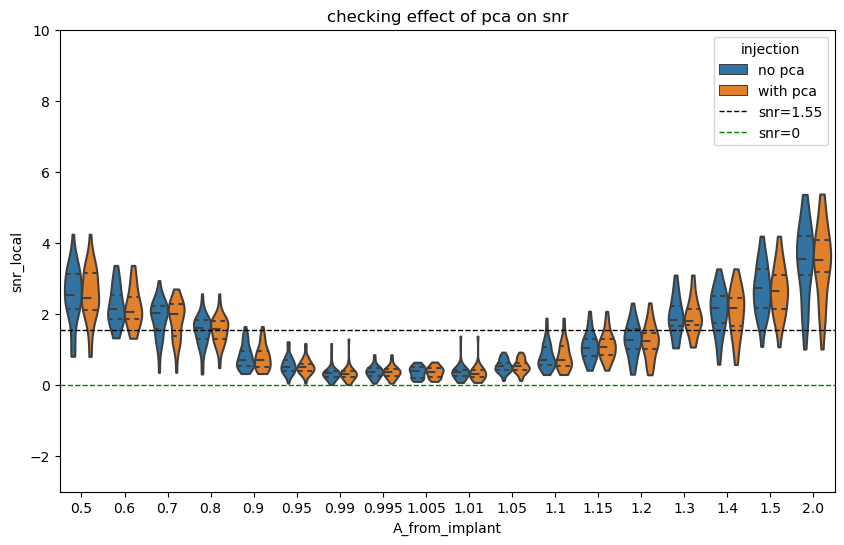

In [189]:

wpca = pd.concat([poss, negs], ignore_index=True)
nopca = pd.concat([poss_nopca, negs_nopca], ignore_index=True)
df_plot1 = nopca.assign(kind="no pca")
df_plot2 = wpca.assign(kind="with pca")
df_plot = pd.concat([df_plot1, df_plot2], ignore_index=True)
df_plot = df_plot[df_plot["snr_local"].notna()]

order = sorted(df_plot["A_from_implant"].unique())

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(
    data=df_plot, x="A_from_implant", y="snr_local", hue="kind",
    order=order, hue_order=["no pca", "with pca"],
    split=False, inner="quartile", cut=0, density_norm="count", ax=ax,
)
ax.axhline(1.55, color="k", ls="--", lw=1, label='snr=1.55')
ax.axhline(0, color="g", ls="--", lw=1, label='snr=0')
ax.set_ylim(-3,10)
ax.set_xlabel("A_from_implant")
ax.set_ylabel("snr_local")
ax.legend(title="injection")
plt.title("checking effect of pca on snr")
plt.show()

In [190]:
nopca

,impl_name,pre,chunk,quad,impl_col,impl_y,status,spliced_name,clean_y,n_changed,...,noise_local_brightening,noise_global_brightening,local_average_outside_brightening,height_brightening,FWHM_brightening,signal_local_brightening,central_point_brightening,point_left_brightening,point_right_brightening,snr_status
0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1144,2420,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,2420,3073,...,15.892234,16.719570,437.168662,178.524942,10.0,37.634620,1408.0,1407.0,1417.0,ok
1,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,1,1974,1278,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,1278,3080,...,47.261668,47.526523,1795.899974,713.761647,17.0,98.027822,2479.0,2470.0,2487.0,ok
2,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,ztf_20221020154120_000640_zi_c08_x,14,3,581,841,ok,lightcurve_ztf_20221020154120_000640_zi_c08_x_...,841,1300,...,212.074501,226.275825,7513.467947,1013.881663,5.0,62.377932,2185.0,2184.0,2189.0,ok
3,lightcurve_ztf_20221020154120_000640_zi_c12_x_...,ztf_20221020154120_000640_zi_c12_x,28,2,3030,2329,ok,lightcurve_ztf_20221020154120_000640_zi_c12_x_...,2329,3079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,chunk at array edge
4,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,ztf_20221020141806_000686_zi_c16_x,20,2,1888,2946,ok,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,2946,3080,...,18.464533,19.246969,536.912724,80.925777,7.0,21.259354,1820.0,1815.0,1822.0,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
768,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,ztf_20221020148032_000686_zg_c05_x,2,2,448,1615,ok,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,1615,3079,...,20.265520,22.294679,701.414154,-28.503083,1.0,5.338828,2057.0,2057.0,2058.0,ok
769,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,ztf_20221020138241_000686_zi_c16_x,1,1,1797,221,ok,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,221,3077,...,16.184491,17.557450,454.155649,-40.113657,2.0,7.801206,1955.0,1954.0,1956.0,ok
770,lightcurve_ztf_20221020294271_000449_zr_c16_x_...,ztf_20221020294271_000449_zr_c16_x,12,1,2271,1530,ok,lightcurve_ztf_20221020294271_000449_zr_c16_x_...,1530,3080,...,12.463196,13.530511,304.581897,-43.388476,4.0,11.747942,384.0,383.0,387.0,ok
771,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,ztf_20221020163819_000640_zg_c12_x,1,2,2060,325,ok,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,325,2853,...,120.792155,130.951001,4690.210818,-1972.994753,17.0,163.522416,689.0,682.0,699.0,ok


Dropped 154 rows with non-ok status; 619 implants used
    amp_med  n_impl  eff      R_ul  R_ul_conservative
0     0.500      43  1.0  0.002996           0.003126
1     0.600      29  1.0  0.002996           0.003191
2     0.700      40  1.0  0.002996           0.003136
3     0.800      42  1.0  0.002996           0.003129
4     0.900      80  1.0  0.002996           0.003065
5     0.995     144  1.0  0.002996           0.003034
6     1.050      62  1.0  0.002996           0.003086
7     1.150      55  1.0  0.002996           0.003097
8     1.300      24  1.0  0.002996           0.003233
9     1.400      70  1.0  0.002996           0.003075
10    2.000      30  1.0  0.002996           0.003184


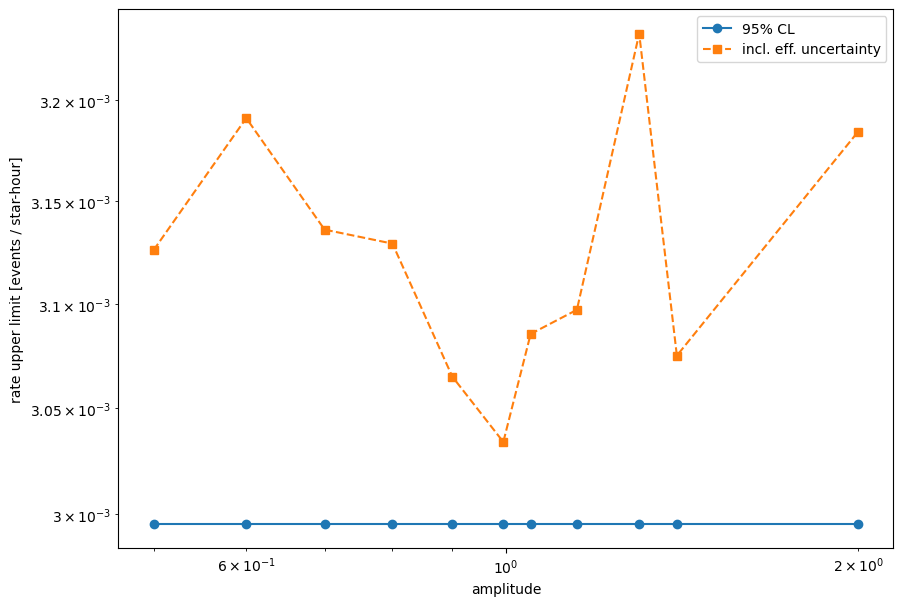

In [193]:
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

def rate_upper_limit(
    df,
    amp_col="A_from_implant",        # <- check: which column is your physical amplitude?
    snr_col="signal_local_brightening",  # <- check: which column is your SNR?
    status_col="snr_status",
    snr_thresh=1.55,
    total_star_hours=None,
    eps_other=1.0,                       # other cuts / dead time
    cl=0.95,
    n_bins=15,
    amp_range=None,                      # (min, max) or None
    ci_alpha=0.32,                       # ~1 sigma on the efficiency
):
    d = df.copy()

    # Rows where SNR couldn't be measured (e.g. "chunk at array edge")
    n_bad = (d[status_col] != "ok").sum() if status_col in d else 0
    d = d[d[snr_col].notna() & d[amp_col].notna()]
    if status_col in d:
        d = d[d[status_col] == "ok"]
    print(f"Dropped {n_bad} rows with non-ok status; {len(d)} implants used")

    d["detected"] = d[snr_col] > snr_thresh

    lo, hi = amp_range or (d[amp_col].min(), d[amp_col].max())
    edges = np.geomspace(lo, hi, n_bins + 1)
    d["bin"] = pd.cut(d[amp_col], edges, include_lowest=True)

    g = d.groupby("bin", observed=True)
    out = pd.DataFrame({
        "n_impl": g.size(),
        "n_det": g["detected"].sum(),
        "amp_med": g[amp_col].median(),
    }).reset_index()

    out["eff"] = out.n_det / out.n_impl * eps_other

    # Clopper-Pearson interval handles 0/n and n/n correctly
    ci = [proportion_confint(k, n, alpha=ci_alpha, method="beta")
          for k, n in zip(out.n_det, out.n_impl)]
    out["eff_lo"] = np.array([c[0] for c in ci]) * eps_other
    out["eff_hi"] = np.array([c[1] for c in ci]) * eps_other

    mu_ul = -np.log(1 - cl)              # 2.996 for 95%
    with np.errstate(divide="ignore"):
        out["R_ul"] = mu_ul / (out.eff * total_star_hours)
        out["R_ul_conservative"] = mu_ul / (out.eff_lo * total_star_hours)
    return out

# usage
res = rate_upper_limit(nopca, total_star_hours=1000)
print(res[["amp_med", "n_impl", "eff", "R_ul", "R_ul_conservative"]])

import matplotlib.pyplot as plt
plt.loglog(res.amp_med, res.R_ul, "o-", label="95% CL")
plt.loglog(res.amp_med, res.R_ul_conservative, "s--", label="incl. eff. uncertainty")
plt.xlabel("amplitude"); plt.ylabel("rate upper limit [events / star-hour]")
plt.legend(); plt.show()